In [30]:
import gc
from scipy.io import loadmat
from probeinterface import Probe
import spikeinterface as si
import spikeinterface.preprocessing as spre
import spikeinterface.extractors as se
import spikeinterface.sorters as ss
import spikeinterface.curation as scur
from spikeinterface.sortingcomponents.motion import estimate_motion, interpolate_motion

import RCP_analysis as rcp
from RCP_analysis.python.functions.config_loading import *

GEOM_PATH = rcp.resolve_probe_geom_path(PARAMS, REPO_ROOT, session_key=None)
NPRW_CFG     = PARAMS.probes.get("NPRW")
INTAN_STREAM = NPRW_CFG.get("neural_data_stream")
RADII        = (NPRW_CFG.get("local_radius_inner"), NPRW_CFG.get("local_radius_outer"))

global_job_kwargs = dict(n_jobs=PARAMS.parallel_jobs, chunk_duration=PARAMS.chunk)
si.set_global_job_kwargs(**global_job_kwargs)
job_kwargs = dict(n_jobs=-1, progress_bar=True, chunk_duration="1s")


# 
#     This script preprocesses the Fastigial Intan data.
#     Input:
#         .rhs files from Intan
#     Output:
#         Checkpoint after preprocessing
#         Checkpoint after thresholding and calculating MUA peak locations and firing rate
# 

In [31]:
# Load Geometry
mat_probe = loadmat(Path(GEOM_PATH))
intan_geom = {"x": mat_probe["xcoords"].ravel(), "y": mat_probe["ycoords"].ravel()}
assert intan_geom["x"].size == intan_geom["y"].size
if "chanMap0ind" not in mat_probe:
    raise ValueError("No 0-based chanmap in .mat geometry file.")
intan_probe_mapping = mat_probe["chanMap0ind"].ravel()
if intan_probe_mapping.size != intan_geom["x"].size:
    raise ValueError("device_index_0based length != #contacts")

nprw_probe = Probe(ndim=2)
nprw_probe.set_contacts(
    positions=np.c_[intan_geom["x"], intan_geom["y"]],
    shapes="square", shape_params={"width": 12.0},
)
nprw_probe.set_device_channel_indices(intan_probe_mapping)

In [32]:
# df = nprw_probe.to_dataframe()
# df

In [33]:
# nprw_probe.device_channel_indices

In [34]:
from tqdm import tqdm
import h5py
import gc
from pathlib import Path
import numpy as np

def generate_template(
    chn_data: np.ndarray,  # (NSTIM, interpulse_len)
    template_mode: str,
    repeat_boundaries: np.ndarray,  # 0-based block boundary indices
    window_size: int = 3,
    pca_k: int = 3,
) -> np.ndarray:
    """Generate pulse-by-pulse artifact templates."""
    NSTIM, interpulse_len = chn_data.shape
    template = np.zeros_like(chn_data)
    w = np.linspace(0, 1, interpulse_len)

    # Build is_first_pulse mask
    is_first_pulse = np.zeros(NSTIM, dtype=bool)
    for b in range(len(repeat_boundaries) - 1):
        is_first_pulse[repeat_boundaries[b]] = True

    if template_mode == "local":
        for i in range(NSTIM):
            if is_first_pulse[i]:
                prev_first_idxs = np.where(is_first_pulse[:i])[0]
                if len(prev_first_idxs) >= 1:
                    n_use = min(3, len(prev_first_idxs))
                    ref_idxs = prev_first_idxs[-n_use:]
                    base = chn_data[ref_idxs].mean(axis=0)
                    t = base - base[0]
                    template[i] = t + w * (-t[-1])
                continue
            count = 0
            j = i - 1
            prev_pulses = []
            while j >= 0 and count < window_size:
                if not is_first_pulse[j]:
                    prev_pulses.append(chn_data[j])
                    count += 1
                j -= 1
            if count > 0:
                base = np.stack(prev_pulses).mean(axis=0)
            else:
                base = np.zeros(interpulse_len)
            t = base - base[0]
            template[i] = t + w * (-t[-1])

    elif template_mode == "pca":
        from sklearn.decomposition import PCA
        num_blocks = len(repeat_boundaries) - 1
        for b in range(num_blocks):
            i_start = repeat_boundaries[b]
            i_end   = repeat_boundaries[b + 1]

            # First pulse correction
            prev_first_idxs = np.where(is_first_pulse[:i_start])[0]
            if len(prev_first_idxs) > 0:
                n_use = min(3, len(prev_first_idxs))
                base = chn_data[prev_first_idxs[-n_use:]].mean(axis=0)
            else:
                base = np.zeros(interpulse_len)
            t = base - base[0]
            template[i_start] = t + w * (-t[-1])

            # PCA on rest of block
            if i_end > i_start + 1:
                pca_indices = np.arange(i_start + 1, i_end)
                X = chn_data[pca_indices]
                X_centered = X - X.mean(axis=1, keepdims=True)
                k = min(pca_k, X_centered.shape[0], X_centered.shape[1])
                pca = PCA(n_components=k)
                score = pca.fit_transform(X_centered)
                recon = pca.inverse_transform(score) + X.mean(axis=1, keepdims=True)
                t = recon - recon[:, [0]]
                drift = w[np.newaxis, :] * (-t[:, [-1]])
                template[pca_indices] = t + drift

    return template


def template_subtraction(
    amplifier_data: np.ndarray,
    trigs: np.ndarray,
    params: dict,
    template_mode: str,
    repeat_boundaries: np.ndarray,
    num_repeats: int,
    num_pulse: int,
) -> tuple[np.ndarray, np.ndarray]:
    """Artifact removal via template subtraction + drift correction.

    Returns:
        amplifier_data: corrected trace, shape (n_samples,)
        template: per-pulse template that was subtracted, shape (NSTIM, interpulse_len)
    """
    amplifier_data = amplifier_data.astype(np.float32, copy=True)

    template_leeway   = params["template_leeway"]
    stim_neural_delay = params["stim_neural_delay"]
    window_size       = params["movmean_window"]
    pca_k             = params["pca_k"]
    NSTIM             = trigs.shape[0]

    trigs_beg = trigs[:, 0]
    trigs_end = trigs[:, 1] + stim_neural_delay

    interpulse_len = int(trigs_end[0] - trigs_beg[0] + 1) + 2 * template_leeway
    chn_data = np.full((NSTIM, interpulse_len), np.nan, dtype=np.float32)

    for i in range(NSTIM):
        seg_start = trigs_beg[i] - template_leeway
        seg_end   = trigs_end[i] + template_leeway
        if seg_start < 0 or seg_end >= len(amplifier_data):
            continue
        chn_data[i] = amplifier_data[seg_start:seg_end + 1]

    block_starts = np.array(repeat_boundaries[:-1], dtype=int)
    block_ends   = np.array(repeat_boundaries[1:],  dtype=int)
    boundaries   = np.concatenate([block_starts, [block_ends[-1]]])

    template = generate_template(chn_data, template_mode, boundaries, window_size, pca_k)

    for i in range(NSTIM):
        seg_start = trigs_beg[i] - template_leeway
        seg_end   = trigs_end[i] + template_leeway
        if seg_start < 0 or seg_end >= len(amplifier_data):
            continue
        amplifier_data[seg_start:seg_end + 1] -= template[i]

    # for i in range(NSTIM - 1):
    #     end_i    = trigs_end[i]
    #     beg_next = trigs_beg[i + 1]
    #     mid1 = int(round((end_i + trigs_beg[i]) / 2))
    #     mid2 = int(round((beg_next + trigs_end[i + 1]) / 2))
    #     if mid1 >= mid2 or mid2 >= len(amplifier_data):
    #         continue
    #     seg_idx = np.arange(mid1, mid2 + 1)
    #     template_end_val = amplifier_data[trigs_end[i]]
    #     n = len(seg_idx)
    #     drift = (np.arange(n, dtype=np.float32) / (n - 1) * (-template_end_val)) if n > 1 else np.zeros(1, dtype=np.float32)
    #     amplifier_data[seg_idx] += drift

    return amplifier_data, template


def template_subtraction_all_parallel(
    neural_data: np.ndarray,
    template_params: dict,
    template_mode: str,
    stim_result,
    n_jobs: int = -1,
    out: np.ndarray | None = None,
) -> tuple[np.ndarray, np.ndarray]:
    """Run template subtraction across all channels, writing results in place to avoid duplicate buffers.

    Returns:
        out: corrected neural data, shape (n_channels, n_samples)
        templates: per-channel, per-pulse templates, shape (n_channels, NSTIM, interpulse_len)
    """
    from joblib import Parallel, delayed

    trigs        = stim_result.trigger_pairs
    block_bounds = stim_result.block_bounds_samples
    n_channels, n_samples = neural_data.shape

    pulse_starts = trigs[:, 0]
    repeat_boundaries = [0]
    for b in range(len(block_bounds)):
        block_end_samp = block_bounds[b, 1]
        in_block = np.where(pulse_starts <= block_end_samp)[0]
        if len(in_block):
            repeat_boundaries.append(int(in_block[-1]) + 1)
    repeat_boundaries = np.array(repeat_boundaries, dtype=int)
    num_repeats = len(repeat_boundaries) - 1
    num_pulse   = trigs.shape[0] / num_repeats

    if out is None:
        out = np.empty_like(neural_data, dtype=np.float32)

    templates = [None] * n_channels

    def process_channel(ch):
        corrected, template = template_subtraction(
            neural_data[ch],
            trigs, template_params, template_mode,
            repeat_boundaries, num_repeats, num_pulse,
        )
        out[ch] = corrected
        templates[ch] = template

    Parallel(n_jobs=n_jobs, prefer="threads")(
        delayed(process_channel)(ch) for ch in tqdm(range(n_channels), desc="artifact correction")
    )
    return out, np.stack(templates).astype(np.float32)

In [35]:
BIN_CKPT = OUT_BASE / "checkpoints" / "NPRW_binary"
BIN_CKPT.mkdir(parents=True, exist_ok=True)

fixed_params = dict(
    NSTIM=0, buffer=25, template_leeway=15,
    stim_neural_delay=13, movmean_window=3,
    med_filt_range=25, gauss_filt_range=25, pca_k=3,
)
STIM_STREAM = NPRW_CFG.get("stim_data_stream")

sess_name = "BL_closed_loop_STIM_003_250528_145904"
sess = INTAN_ROOT / sess_name
bin_path = BIN_CKPT / f"{sess.name}_neural.bin"

In [37]:
BIN_CKPT

PosixPath('/home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/checkpoints/NPRW_binary')

In [38]:
DRIFT_CKPT = OUT_BASE / "checkpoints" / "NPRW_drift"
SORT_CKPT  = OUT_BASE / "checkpoints" / "sorting_results" / f'{sess_name}_blanking'
DRIFT_CKPT.mkdir(parents=True, exist_ok=True)
SORT_CKPT.mkdir(parents=True, exist_ok=True)

In [39]:
# load Intan data
rec_raw = se.read_split_intan_files(sess, mode="concatenate", stream_name=INTAN_STREAM, use_names_as_ids=True)
rec_raw = spre.unsigned_to_signed(rec_raw)
rec_raw = rec_raw.set_probe(nprw_probe)
rec_raw = rcp.reorder_recording_to_geometry(rec_raw, intan_probe_mapping)
print(rec_raw)

ChannelSliceRecording: 128 channels - 30.0kHz - 1 segments - 11,636,480 samples 
                       387.88s (6.46 minutes) - int16 dtype - 2.77 GiB


In [ ]:
# get traces
neural_data = rec_raw.get_traces().T  # (n_channels, n_samples)
print(neural_data.shape, neural_data.dtype)

In [ ]:
# extract stim triggers
import numpy as np
stim_npz_path = NPRW_AUX_DATA / f"{sess.name}_Intan_streams" / "stim_stream.npz"

if stim_npz_path.exists():
    print(f"loading cached stim arrays from {stim_npz_path}")
    loaded = np.load(stim_npz_path, allow_pickle=True)
    stim_arrays = {k: loaded[k] for k in loaded.files if k != "meta"}
else:
    print("no cached stim arrays found, running extraction")
    stim_arrays = rcp.extract_stim_npz(
        sess=sess, out_dir=NPRW_AUX_DATA,
        stim_stream_name=STIM_STREAM,
        chanmap_perm=intan_probe_mapping,
    )
print(stim_arrays.keys())
print(stim_arrays["trigger_pairs"].shape)

loading cached stim arrays from /home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/aux_data/NPRW/BL_closed_loop_STIM_003_250528_145904_Intan_streams/stim_stream.npz
dict_keys(['stim_traces', 'active_channels', 'trigger_pairs', 'block_bounds_samples', 'pulse_sizes'])
(9680, 2)


In [ ]:
stim_result = rcp.StimTriggerResult(
    active_channels=stim_arrays["active_channels"],
    trigger_pairs=stim_arrays["trigger_pairs"],
    block_bounds_samples=stim_arrays["block_bounds_samples"],
    pulse_sizes=stim_arrays["pulse_sizes"],
)

import pickle
with open(SORT_CKPT / "stim_result.pkl", "wb") as f:
    pickle.dump(stim_result, f)

In [ ]:
if 'neural_data_corrected' in dir():
    del neural_data_corrected
gc.collect()

103

In [ ]:
# Artifact correction
fixed_params = dict(
    NSTIM=0, buffer=25, template_leeway=12,
    stim_neural_delay=13, movmean_window=3,
    med_filt_range=25, gauss_filt_range=25, pca_k=3,
)

neural_data_corrected, templates = template_subtraction_all_parallel(
    neural_data=neural_data,
    template_params=fixed_params,
    template_mode="pca",
    stim_result=stim_result,
    n_jobs=2,
)
print(neural_data_corrected.shape, neural_data_corrected.dtype)
print(templates.shape, templates.dtype)

artifact correction: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 128/128 [00:37<00:00,  3.38it/s]


(128, 11636480) float32
(128, 9680, 44) float32


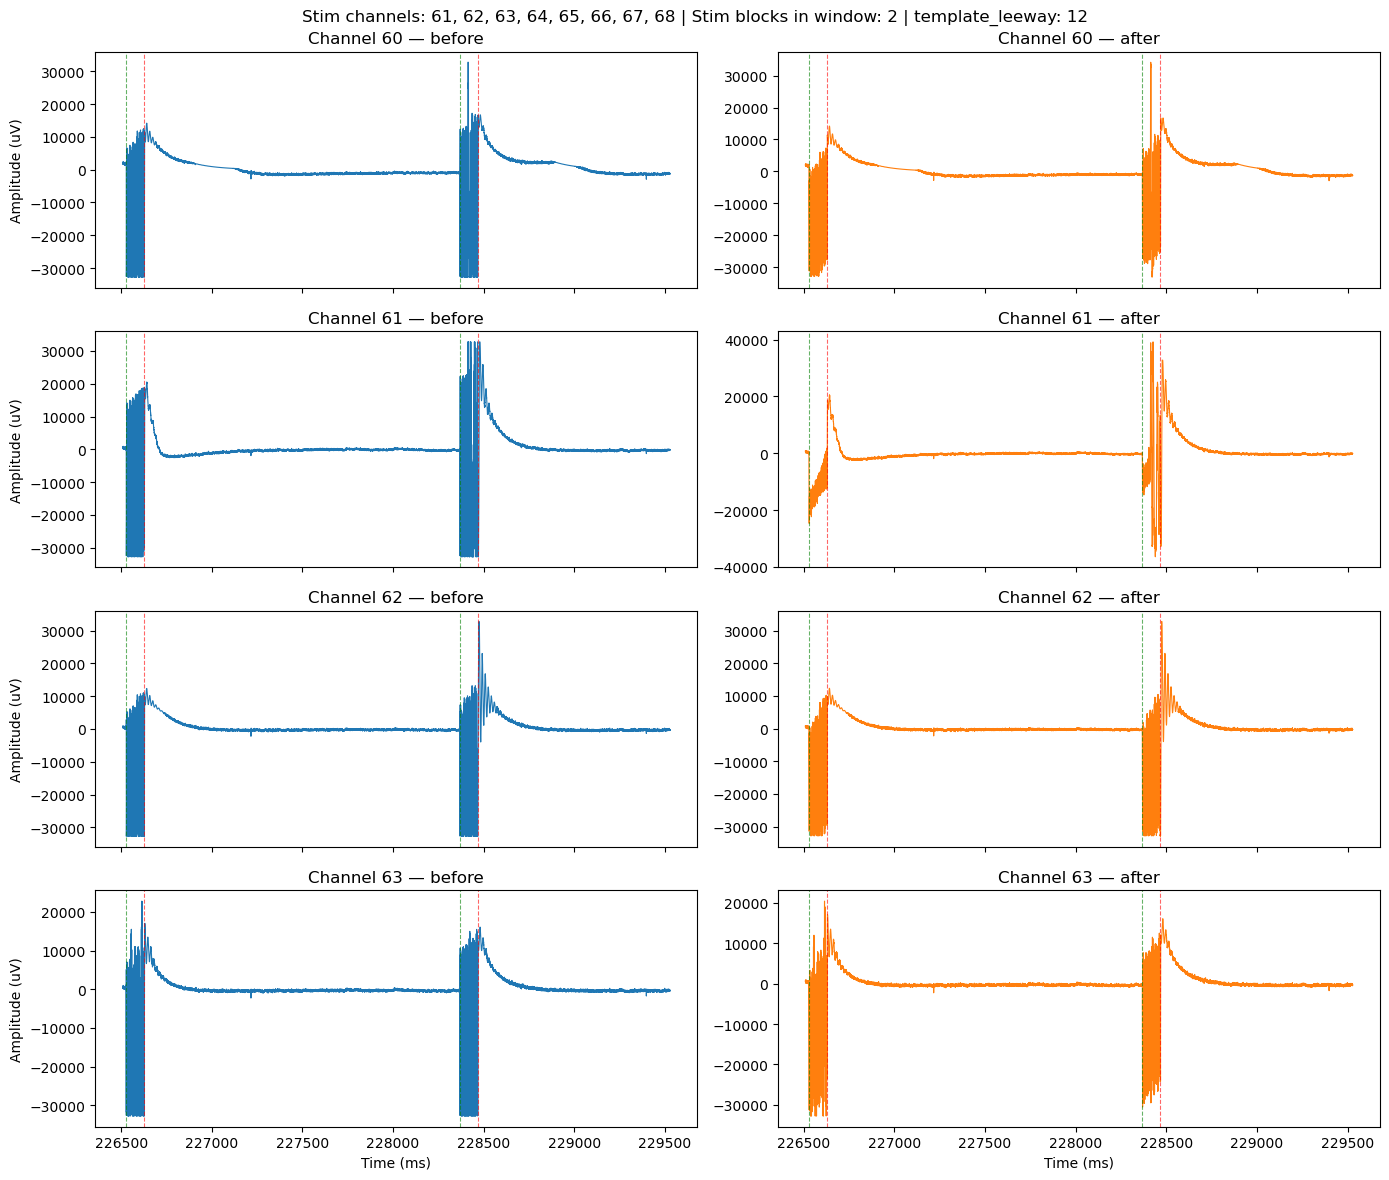

In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt

channels = [60, 61, 62, 63] #[1, 2, 3, 4]
fs = 30000.0
block_idx = 151

ms_before = 20
ms_after  = 3000

block_bounds = stim_result.block_bounds_samples
center = block_bounds[block_idx, 0]  # block start sample

w_start = max(0, center - int(ms_before / 1000 * fs))
w_end   = min(neural_data.shape[1], center + int(ms_after / 1000 * fs))
t = np.arange(w_start, w_end) / fs * 1000

in_window = (block_bounds[:, 0] <= w_end) & (block_bounds[:, 1] >= w_start)
n_blocks_in_window = np.sum(in_window)
template_leeway = fixed_params["template_leeway"]

fig, axes = plt.subplots(len(channels), 2, figsize=(14, 3 * len(channels)), sharex=True)

for row, ch in enumerate(channels):
    axes[row, 0].plot(t, neural_data[ch, w_start:w_end], linewidth=0.8, color="tab:blue")
    axes[row, 0].set_title(f"Channel {ch} — before")
    axes[row, 0].set_ylabel("Amplitude (uV)")

    axes[row, 1].plot(t, neural_data_corrected[ch, w_start:w_end], linewidth=0.8, color="tab:orange")
    axes[row, 1].set_title(f"Channel {ch} — after")

    for ax in (axes[row, 0], axes[row, 1]):
        for b_start, b_end in block_bounds:
            if w_start <= b_start <= w_end:
                ax.axvline(b_start / fs * 1000, color="green", linestyle="--", alpha=0.6, linewidth=0.8)
            if w_start <= b_end <= w_end:
                ax.axvline(b_end / fs * 1000, color="red", linestyle="--", alpha=0.6, linewidth=0.8)

axes[-1, 0].set_xlabel("Time (ms)")
axes[-1, 1].set_xlabel("Time (ms)")

active_str = ", ".join(str(c) for c in sorted(stim_result.active_channels.tolist()))
fig.suptitle(f"Stim channels: {active_str} | Stim blocks in window: {n_blocks_in_window} | template_leeway: {template_leeway}")

plt.tight_layout()
plt.show()

In [16]:
print("stim timing", block_bounds[1:5, 1] / 30000)

stim timing [13.78003333 14.21083333 15.7109     16.05076667]


In [17]:
import gc

if 'neural_data' in dir():
    del neural_data
if 'templates' in dir():
    del templates

gc.collect()

55

In [18]:
import spikeinterface as si
import spikeinterface.preprocessing as spre

fs = 30000.0

rec_corrected = si.NumpyRecording(
    traces_list=neural_data_corrected.T,
    sampling_frequency=fs,
)
rec_corrected = rec_corrected.set_probe(nprw_probe)

rec_bp = spre.bandpass_filter(rec_corrected, freq_min=float(PARAMS.highpass_hz), freq_max=float(PARAMS.lowpass_hz))
rec_cmr = spre.common_reference(rec_bp, reference="local", operator="median", local_radius=(RADII[0], RADII[1]))

print(rec_cmr)

CommonReferenceRecording: 128 channels - 30.0kHz - 1 segments - 11,636,480 samples 
                          387.88s (6.46 minutes) - float32 dtype - 5.55 GiB


noise_level (workers: 12 processes fork):   0%|          | 0/20 [00:00<?, ?it/s]

detect and localize (workers: 12 processes fork):   0%|          | 0/388 [00:00<?, ?it/s]

Cross correlation:   0%|          | 0/3 [00:00<?, ?it/s]

Solve:   0%|          | 0/2 [00:00<?, ?it/s]

interpolate_motion (InterpolateMotionRecording): 128 channels - 30.0kHz - 1 segments 
                    11,636,480 samples - 387.88s (6.46 minutes) - float32 dtype - 5.55 GiB

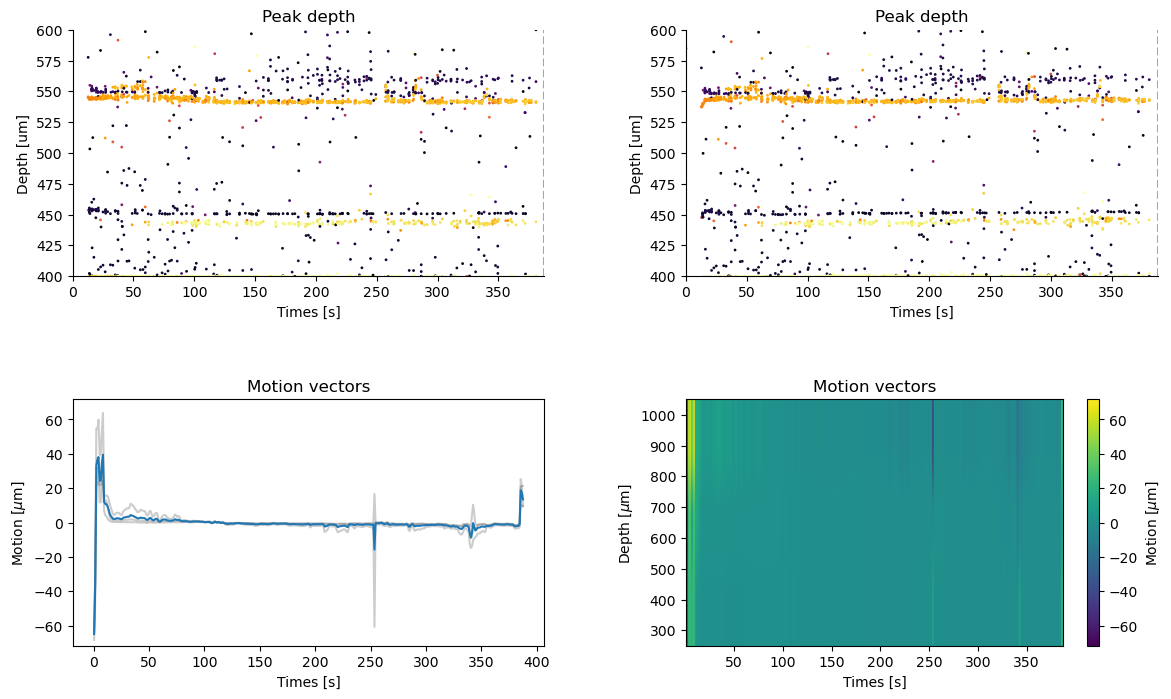

In [19]:
import matplotlib.pyplot as plt
plt.ion()
motion, motion_info = spre.compute_motion(
    rec_cmr, preset="dredge", folder=DRIFT_CKPT, output_motion_info=True, overwrite=True, **job_kwargs
)

import pickle

with open(SORT_CKPT / "motion_info.pkl", "wb") as f:
    pickle.dump(motion_info, f)


%matplotlib inline
from spikeinterface.widgets import plot_motion, plot_motion_info
fig = plt.figure(figsize=(14, 8))
plot_motion_info(
    motion_info, rec_cmr,
    figure=fig,
    depth_lim=(400, 600),
    color_amplitude=True,
    amplitude_cmap="inferno",
    scatter_decimate=10,
)

from spikeinterface.sortingcomponents.motion import interpolate_motion
interpolated_recording = interpolate_motion(
    recording=rec_cmr, motion=motion_info['motion'],
    border_mode="force_extrapolate"
)
interpolated_recording

In [21]:
import gc

for name in ['neural_data_corrected', 'motion_info', 'interpolated_recording', 'rec_bp']:
    if name in dir():
        del globals()[name]

gc.collect()

2910

In [22]:
rec_cmr_path = SORT_CKPT / "rec_cmr_saved"
rec_cmr_saved = rec_cmr.save(folder=rec_cmr_path, overwrite=True, **job_kwargs)
print(f"saved -> {rec_cmr_path}")

write_binary_recording 
engine=process - n_jobs=12 - samples_per_chunk=30,000 - chunk_memory=14.65 MiB - total_memory=175.78 MiB - chunk_duration=1.00s


/home/bryan/miniconda3/envs/pipeline/lib/python3.10/site-packages/spikeinterface/core/base.py:991: UserWarning: The extractor is not serializable to file. The provenance will not be saved.
  warnings.warn("The extractor is not serializable to file. The provenance will not be saved.")


write_binary_recording (workers: 12 processes fork):   0%|          | 0/388 [00:00<?, ?it/s]

saved -> /home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/checkpoints/sorting_results/BL_closed_loop_STIM_003_250528_145904_blanking/rec_cmr_saved


In [9]:
import pickle
import spikeinterface as si

rec_cmr_saved = si.load(SORT_CKPT / "rec_cmr_saved")

with open(SORT_CKPT / "motion_info.pkl", "rb") as f:
    motion_info = pickle.load(f)

with open(SORT_CKPT / "stim_result.pkl", "rb") as f:
    stim_result = pickle.load(f)

print(rec_cmr_saved)
print(motion_info.keys() if hasattr(motion_info, "keys") else type(motion_info))
print(stim_result.trigger_pairs.shape)

BinaryFolderRecording: 128 channels - 30.0kHz - 1 segments - 11,636,480 samples 
                       387.88s (6.46 minutes) - float32 dtype - 5.55 GiB
dict_keys(['parameters', 'run_times', 'peaks', 'peak_locations', 'motion'])
(9680, 2)


In [ ]:
ARTRMV_MS_BEFORE = float(PARAMS.remove_ms_before) if hasattr(PARAMS, "remove_ms_before") else 20.0
ARTRMV_TAIL_MS   = float(PARAMS.remove_tail_ms_after) if hasattr(PARAMS, "remove_tail_ms_after") else 20.0

fs = rec_cmr_saved.sampling_frequency
stim_channels = stim_result.active_channels
pulse_onsets = stim_result.trigger_pairs[:, 0]

all_channel_ids = rec_cmr_saved.channel_ids
print(all_channel_ids[:5], all_channel_ids.dtype)
print(stim_channels[:5], stim_channels.dtype)

non_stim_channel_ids = [ch for ch in all_channel_ids if ch not in stim_channels]
stim_channel_ids = [ch for ch in all_channel_ids if ch in stim_channels]

rec_stim_subset = rec_cmr_saved.select_channels(stim_channel_ids)
rec_nonstim_subset = rec_cmr_saved.select_channels(non_stim_channel_ids)

[0 1 2 3 4] int64
[61 62 63 64 65] int32


In [ ]:
rec_stim_blanked = si.preprocessing.remove_artifacts(
    rec_stim_subset,
    list_triggers=pulse_onsets.tolist(),
    ms_before=ARTRMV_MS_BEFORE,
    ms_after=ARTRMV_TAIL_MS,
    mode="zeros",
)

from spikeinterface.core import aggregate_channels
# Build blanked array preserving original channel order
import numpy as np

blanked_traces = rec_cmr_saved.get_traces().copy()  # (n_samples, n_channels), geometry order preserved
stim_blanked_traces = rec_stim_blanked.get_traces()  # (n_samples, n_stim_channels)

stim_idx_positions = [list(all_channel_ids).index(ch) for ch in stim_channel_ids]
blanked_traces[:, stim_idx_positions] = stim_blanked_traces

rec_artif_removed = si.NumpyRecording(traces_list=blanked_traces, sampling_frequency=rec_cmr_saved.sampling_frequency)
rec_artif_removed = rec_artif_removed.set_probe(nprw_probe)

print(rec_artif_removed)

In [22]:
# Save the corrected recording to disk so it's serializable for the sorter
saved_rec_path = SORT_CKPT / "rec_corrected_saved"

rec_corrected_saved = rec_cmr_saved.save(
    folder=saved_rec_path,
    overwrite=True,
    **job_kwargs,
)
print(rec_corrected_saved)

write_binary_recording 
engine=process - n_jobs=12 - samples_per_chunk=30,000 - chunk_memory=14.65 MiB - total_memory=175.78 MiB - chunk_duration=1.00s


write_binary_recording (workers: 12 processes fork):   0%|          | 0/388 [00:00<?, ?it/s]

BinaryFolderRecording: 128 channels - 30.0kHz - 1 segments - 11,636,480 samples 
                       387.88s (6.46 minutes) - float32 dtype - 5.55 GiB


In [23]:
# Kilosort4
sorting = ss.run_sorter(
    sorter_name="kilosort4",
    recording=rec_corrected_saved,
    folder=SORT_CKPT / "folder_KS4",
    remove_existing_folder=True,
    do_correction=False,
)
sorting = scur.remove_duplicated_spikes(sorting)
sorting = scur.remove_excess_spikes(sorting, rec_corrected_saved)
sorting = scur.remove_redundant_units(sorting, align=False, remove_strategy="max_spikes")
sorting.save(folder=SORT_CKPT / "sorting_curated", overwrite=True)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:10<00:00, 10.18s/it]
/home/bryan/miniconda3/envs/pipeline/lib/python3.10/site-packages/spikeinterface/core/basesorting.py:384: UserWarning: The registered recording will not be persistent on disk, but only available in memory
  warnings.warn("The registered recording will not be persistent on disk, but only available in memory")


NumpyFolder (NumpyFolderSorting): 301 units - 1 segments - 30.0kHz

In [24]:
# Reload
# sorting = si.load(SORT_CKPT / "sorting_curated")

In [ ]:
if 'analyzer_precuration' in dir():
    del analyzer_precuration
gc.collect()
import shutil, pathlib
folder = SORT_CKPT / "analyzer_blanking"
if folder.exists():
    shutil.rmtree(folder, ignore_errors=True)
    # force-remove anything left
    import subprocess
    subprocess.run(["rm", "-rf", str(folder)], check=True)

analyzer_precuration = si.create_sorting_analyzer(
    sorting, rec_corrected_saved,
    format="binary_folder",
    folder=SORT_CKPT / "analyzer_blanking",
    overwrite=True,
    **job_kwargs,
)
analyzer_precuration.compute(
    ["random_spikes", "waveforms", "templates", "noise_levels", "spike_amplitudes", "unit_locations"],
    **job_kwargs,
)
analyzer_precuration.compute("isi_histograms")
analyzer_precuration.compute("correlograms", window_ms=100, bin_ms=5.0)
analyzer_precuration.compute(
    "principal_components", n_components=3, mode="by_channel_global", whiten=True, **job_kwargs
)
analyzer_precuration.compute("quality_metrics", metric_names=["snr", "firing_rate"])
analyzer_precuration.compute("template_similarity")


estimate_sparsity (workers: 12 processes fork):   0%|          | 0/388 [00:00<?, ?it/s]

/home/bryan/miniconda3/envs/pipeline/lib/python3.10/site-packages/spikeinterface/core/basesorting.py:384: UserWarning: The registered recording will not be persistent on disk, but only available in memory
  warnings.warn("The registered recording will not be persistent on disk, but only available in memory")


compute_waveforms (workers: 12 processes fork):   0%|          | 0/388 [00:00<?, ?it/s]

noise_level (workers: 12 processes fork):   0%|          | 0/20 [00:00<?, ?it/s]

Compute : spike_amplitudes (workers: 12 processes fork):   0%|          | 0/388 [00:00<?, ?it/s]

Fitting PCA:   0%|          | 0/301 [00:00<?, ?it/s]

Projecting waveforms:   0%|          | 0/301 [00:00<?, ?it/s]

/home/bryan/miniconda3/envs/pipeline/lib/python3.10/site-packages/spikeinterface/postprocessing/template_similarity.py:345: NumbaTypeSafetyWarning: unsafe cast from uint64 to int64. Precision may be lost.
  overlapping_ids = overlapping_j_list[i]


SortingAnalyzer: 128 channels - 76 units - 1 segments - binary_folder - sparse - has recording
Loaded 11 extensions: random_spikes, waveforms, templates, noise_levels, unit_locations, isi_histograms, correlograms, principal_components, quality_metrics, template_similarity, spike_amplitudes

In [ ]:
from spikeinterface.exporters import export_to_phy
export_to_phy(
    analyzer_precuration,
    output_folder=SORT_CKPT / "phy_blanking",
    remove_if_exists=True,
    **job_kwargs,
)
print(f"Phy export -> {SORT_CKPT / 'phy_blanking'}")

write_binary_recording (workers: 12 processes fork):   0%|          | 0/388 [00:00<?, ?it/s]

extract PCs (workers: 12 processes fork):   0%|          | 0/388 [00:00<?, ?it/s]

Run:
phy template-gui  /home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/checkpoints/sorting_results/BL_closed_loop_STIM_003_250528_145904_blanking/phy_blanking/params.py
Phy export -> /home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/checkpoints/sorting_results/BL_closed_loop_STIM_003_250528_145904_blanking/phy_blanking


In [ ]:
sorting.get_unit_spike_train(unit_id=1)

array([  0,   1,   2,   3,   4,   5,   6,   8,  10,  11,  14,  15,  16,
        17,  18,  19,  22,  23,  24,  25,  26,  27,  28,  29,  30,  31,
        32,  33,  34,  35,  36,  37,  39,  41,  42,  43,  44,  45,  46,
        47,  48,  49,  51,  52,  53,  54,  55,  56,  57,  58,  59,  60,
        61,  62,  63,  64,  65,  66,  67,  68,  69,  70,  72,  73,  74,
        75,  76,  77,  78,  79,  81,  82,  83,  84,  85,  86,  87,  89,
        90,  91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102,
       103, 104, 105, 106, 107, 108, 110, 111, 113, 114, 115, 116, 117,
       118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130,
       131, 132, 133, 134, 135, 136, 137, 138, 139, 141, 142, 143, 144,
       145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157,
       158, 159, 160, 161, 162, 163, 166, 167, 168, 169, 170, 172, 173,
       174, 175, 176, 177, 178, 179, 180])